In [ ]:
import tensorflow as tf
import xml.etree.ElementTree as ET

from keras import Sequential
from keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    Input,
    Resizing

    )

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

#keras applications met à disposition des modèles
#avec leur poids pré entraînés
from tensorflow.keras.applications import VGG16 as KerasVGG16
from tensorflow.keras.applications.vgg16 import preprocess_input


In [ ]:
import os

In [ ]:
!pip install cython
#!pip install git+https://github.com/MiraPurkrabek/pydensecrf_fork.git
!pip install simplecrf

  Using cached SimpleCRF-0.2.1.1.tar.gz (2.7 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for simplecrf (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for simplecrf
Failed to build simplecrf
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (simplecrf)


In [ ]:
from google.colab import drive
drive.mount( '/content/drive',force_remount=True )

Mounted at /content/drive


In [ ]:
#Dossier du dataset
DATA_DIR="/content/drive/MyDrive/Deeplab-RCP209/Dataset/segmentation-pascal-voc-2012/VOC2012_train_val/VOC2012_train_val"

# Dossier où sauvegarder les modèles
SAVE_DIR = "/content/drive/MyDrive/Deeplab-RCP209/Models"

#os.makedirs(SAVE_DIR, exist_ok=True)

In [ ]:

# Les 20 classes de Pascal VOC (ordre alphabétique = ordre standard)
VOC_CLASSES = [
    "fond","aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor",
]

#dictionnaire : permet d'obtenir l'indice de la classe
#CLASS_TO_IDX = {"aeroplane": 0, "bicycle": 1, ..... "tvmonitor": 19 }
CLASS_TO_IDX = {name: i for i, name in enumerate(VOC_CLASSES)}

#nombre de classe du dataset segmentation avec la classe de fond à 0
NUM_CLASSES = 21


#TODO verifier utilisation de ces constantes
#hyperparameter
BATCH_SIZE = 16
#IMAGE_SIZE = 224 # taille d'image pour la classification VGG16
IMAGE_SIZE = 321  # 321 taille retenue par les auteurs deeplab pour Pascal VOC, une autre taille est possible en entrée du réseau convolutif.

#EPOCHS = 30
#EPOCHS = 10

EPOCHS = 100


#learning rate
# valeurs de plage à tester successivement : 1e-5 , 3e-5, 1e-4 , 3e-4 , 1e-3
#essai 1
#LR = 1e-3
#essai 2
#LR = 3e-4
#essai 3
#LR = 1e-4
#essai 4
#LR = 3e-5
#essai 5
#LR = 1e-5

#*********************
#LR final fixé
LR = 1e-4
#***********************

# valeurs de plage = tester : 0.0 0.3 0.5 0.7
# rappel valeur pour Essai 3
#DROPOUT = 0.7

#essai 6
#DROPOUT = 0.5

#essai 7
#DROPOUT = 0.3


#essai 8
#DROPOUT = 0.0

#*********************
#dropout final fixé
DROPOUT = 0.3
#***********************

#taux de dilatation (Dilation rate ) des essais 1 - 8
#DILATION_RATE = 24

#essai 9
#DILATION_RATE = 12   #le chois des auteurs deeplab


#essai 10
#DILATION_RATE = 18

#essai 11
#DILATION_RATE = 6

#*********************
#taux de dilalation final fixé
DILATION_RATE = 24
#***********************



**FONCTION DE PERTE**

In [ ]:
# SparseCategoricalCrossentropy attend des labels entiers comme ceux
# des masques de Pascal VOC
def segmentation_loss(ignore_label=255):
  return tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=ignore_label)

**FONCTION METRIQUE**

In [ ]:
def metrique_MeanIoU(ignore_label=255):
  return tf.keras.metrics.MeanIoU(num_classes=NUM_CLASSES, ignore_class=ignore_label, sparse_y_pred=False, name="miou")


**MODELE**

In [ ]:

##################################################
## Classe du modèle
#################################################
#
#  Paramètres
#  ----------
#  input_shape : tuple
#      Dimensions de l'image d'entrée (hauteur, largeur, canaux).
#      Par défaut (224, 224, 3) comme dans l'article original.
#  num_classes : int
#      Nombre de classes en sortie (1000 pour ImageNet).
#  dropout_rate : float
#      Taux de dropout appliqué dans les couches denses.
#

class Deeplab:
  def __init__(self,input_shape=(IMAGE_SIZE,IMAGE_SIZE,3), num_classes=NUM_CLASSES, dropout_rate=DROPOUT):
    self.input_shape  = input_shape
    self.num_classes  = num_classes
    self.dropout_rate = dropout_rate
    self.model = self.build_model()

  # bloc de convolution Conv2D + MaxPooling
  # N couches 2D suivies d'un MaxPooling
  def conv_block_2D_MaxPool(self, model, filters, num_convs, stride):
    for _ in range(num_convs):
      model.add(Conv2D(filters=filters, kernel_size=(3, 3), padding="same",activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2),padding="same", strides=(stride,stride)))


  # construction du modèle,
  def build_model(self):

    #modèle de type séquentiel
    model = Sequential(name="Deeplab")

    #couche d'entrée - Tensor
    model.add(Input(shape=self.input_shape))

    # partie convolutive de 5 blocs, chaque bloc constitué de (num_convs) couches conv2D suivies d'une couche max pooling
    #bloc 1
    self.conv_block_2D_MaxPool( model, filters=64, num_convs=2, stride=2)  # bloc 1
    #bloc 2
    self.conv_block_2D_MaxPool(model, filters=128, num_convs=2, stride=2)  # bloc 2
    #bloc 3
    self.conv_block_2D_MaxPool(model, filters=256, num_convs=3, stride=2)  # bloc 3
    #bloc 4
    self.conv_block_2D_MaxPool(model, filters=512, num_convs=3, stride=1)  # bloc 4 avec un stride à 1 au lieu de 2, le sous-échantillonnage est alors réduit
                                                                           # pour conserver des cartes de carctéristiques de plus haute résolution
    #bloc 5 sans pooling, atrous avec le paramètre dilation_rate à 2
    model.add(Conv2D(filters=512, kernel_size=(3, 3), padding="same",activation="relu", dilation_rate=2))
    model.add(Conv2D(filters=512, kernel_size=(3, 3), padding="same",activation="relu", dilation_rate=2))
    model.add(Conv2D(filters=512, kernel_size=(3, 3), padding="same",activation="relu", dilation_rate=2))

    # ex bloc 5 du VGG16 remplacé par des couches 2D à trous, à conserver pour mémoire
    #self.conv_block_2D_MaxPool(model, filters=512, num_convs=3)  # bloc 5

    # fc6 fully connected de VGG16 devient une convolution à trous  kernel 3,3, dilation_rate à 12
    model.add(Conv2D(filters=1024, kernel_size=(3, 3), padding="same",activation="relu", dilation_rate=DILATION_RATE))
    model.add(Dropout(rate=self.dropout_rate))
    # fc7 fully connected de VGG16 devient une convolution  kernel 1,1
    model.add(Conv2D(filters=1024, kernel_size=(1, 1), padding="same",activation="relu"))
    model.add(Dropout(rate=self.dropout_rate))
    # la couche final de classification de VGG16 dvient une carte de score (score map) = logits ou scores brut
    model.add(Conv2D(filters=NUM_CLASSES, kernel_size=(1, 1), padding="same"))

    # pour mémoire partie VGG16 couches entièrement connectées (Fully connected) de 3 couches
    #model.add(Flatten())
    #fc6 fully connected
    #model.add(Dense(units=4096, activation="relu"))
    #model.add(Dropout(rate=self.dropout_rate))
    #fc7 fully connected
    #model.add(Dense(units=4096, activation="relu"))
    #model.add(Dropout(rate=self.dropout_rate))
    # final dense layer for classification 8
    #model.add(Dense(units=self.num_classes, activation="softmax"))

    #augmentation de la résolution pour retrouver la résolution d'origine
    #avec interpolation bilinéaire, facteur 8
    #model.add(UpSampling2D(size=(8, 8), interpolation='bilinear', name='upsample'))

    model.add(Resizing(self.input_shape[0], self.input_shape[1], interpolation='bilinear',name='upsample'))
    return model


  # compilation du modèle
  # avec une fonction de loss custom ignorant les valeurs 255, basée sur une cross entropy softmax par pixel
  def compile_model(self):
    self.model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
                       loss=segmentation_loss(ignore_label=255),
                       metrics=[metrique_MeanIoU(ignore_label=255)])
    return self.model

  # résumé du modèle
  def summary(self):
      """Affiche un résumé de l'architecture."""
      self.model.summary()

  # obtention du modèle
  def get_model(self):
      """Retourne l'objet modèle Keras."""
      return self.model

  # chargement poids pré entrainés Vgg16 bloc 1 à 5
  def chargement_poids_vgg16(self):
    #top à false pour ne pas charger les 3 fully connected layers spécifiques à VGG16
    # le modèle VGG16 est préentraîné sur Imagenet
    model_ref_VGG16 = KerasVGG16(weights="imagenet", include_top=False, input_shape=self.input_shape)

    couche_conv_vgg16 = [l for l in model_ref_VGG16.layers if isinstance(l, Conv2D) ]
    couche_conv_deeplab = [l for l in self.model.layers if isinstance(l, Conv2D) ]

    # on remplace les poids sur les 13 premières couche conv2D (bloc 1 à 5)
    for couche_vgg16, couche_deeplab in zip(couche_conv_vgg16, couche_conv_deeplab[:13]):
      couche_deeplab.set_weights(couche_vgg16.get_weights())
    print("Poids VGG16 Imagenet copiés dans 13 couches Conv.........")

    return self.model

**CHARGEMENT DES DONNEES PASCAL VOC**

In [ ]:
class VOCDataLoader:
# construction de dataset tensorflow

  def __init__(self, data_dir, batch_size=32, image_size=(IMAGE_SIZE, IMAGE_SIZE), ignore_label=255):
    self.data_dir = data_dir
    self.batch_size = batch_size
    self.image_size = image_size

    self.images_dir = os.path.join(data_dir, "JPEGImages")
    #segmentation : masques png + splits du dataset dans /Segmentation/
    self.masks_dir = os.path.join(data_dir, "SegmentationClass")
    self.splits_dir = os.path.join(data_dir, "ImageSets", "Segmentation")

    self._check_structure()

  # _check_structure vérifie que les dossiers existent
  def _check_structure(self):
      for path in (self.images_dir, self.masks_dir, self.splits_dir):
          if not os.path.isdir(path):
              raise FileNotFoundError(
                  f"Dossier introuvable : {path}\n"
                  f"Vérifier l'existence des répertoires JPEGImages/, SegmentationClass/, "
                  f"et ImageSets/Segmentation/ sous {self.data_dir}"
              )

  # récupération des identifiants d'images depuisImageSets/Segmentation/{split}.txt
  def _read_split_ids(self, split):
    split_file = os.path.join(self.splits_dir, f"{split}.txt")
    if not os.path.isfile(split_file):
        raise FileNotFoundError(f"Fichier de split introuvable : {split_file}")
    with open(split_file, "r") as f:
       return [line.strip() for line in f if line.strip()]

  #Construit les listes (chemins d'images, labels multi-hot) pour un split.
  def _build_lists(self, split):
    ids = self._read_split_ids(split)
    images_paths, masks_paths = [], []
    for image_id in ids:
        img_path = os.path.join(self.images_dir, f"{image_id}.jpg")
        mask_path = os.path.join(self.masks_dir, f"{image_id}.png")
        if os.path.isfile(img_path) and os.path.isfile(mask_path):
            images_paths.append(img_path)
            masks_paths.append(mask_path)
    return images_paths, masks_paths

  # lecture du masque avec PIL -> indices de classe bruts (H, W) int32
  # via tf.numpy_function, reçoit directement un objet bytes
  # tf.numpy_function permet de sortir du graphe tensorflow et d'appeler
  # une fonction et de récupérer son résultat
  @staticmethod
  def _read_mask_pil(path_bytes):
    path = path_bytes.decode("utf-8")
    return np.array(Image.open(path)).astype(np.int32)


  #charge une image, la redimensionne et la normalize
  def _load_and_preprocess_image(self, image_path, mask_path):
    # image JPEG : resize bilinéaire puis normalisation sur intervalle [0,1]
    image = tf.io.read_file(image_path)
    #Decode a JPEG-encoded image to a uint8 tensor.
    image = tf.image.decode_jpeg(image, channels=3)

    #redimensionnement
    image = tf.image.resize(image, self.image_size)

    #normalisation vers [0,1] -> essai from scratch
    #image = tf.cast(image, tf.float32) / 255.0

    #dans le cas du chargement de poids Vgg16 préentrainés (non normalisés)
    image = tf.cast(image, tf.float32)


    # Masque : lecture PIL (les indices sont préservés avec ce type de lecture)
    mask = tf.numpy_function(self._read_mask_pil, inp=[mask_path], Tout=tf.int32)
    mask.set_shape([None, None])   # la forme est perdu avec numpy_function
    mask = mask[..., tf.newaxis]   # (H,W,1) pour le resize
    #redimensionnement, ne pas utiliser bilinéaire
    mask = tf.image.resize(mask, self.image_size, method="nearest")
    mask = tf.cast(mask[..., 0], tf.int32) # retour (H, W) pour le resize

    return image, mask

  #obtention du dataset prêt pour l'entrainement/validation
  def get_dataset(self, split, shuffle=True):
    images_paths, mask_paths = self._build_lists(split)

    print(f"[{split}] {len(images_paths)} paires image/masque chargées.")

    ds = tf.data.Dataset.from_tensor_slices((images_paths, mask_paths))

    if shuffle:
      ds = ds.shuffle(buffer_size=min(len(images_paths), 2000))

    #les images sont resizer et normalisés, en // en fonction disponibilité processuer
    ds = ds.map(self._load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    # les éléments du dataset sont combinés en batchs
    ds = ds.batch(self.batch_size)
    # prélecture des données de l'étape suivante
    ds = ds.prefetch(buffer_size=tf.data.AUTOTUNE)

    return ds



**ENTRAINEMENT DU MODELE**

In [ ]:
# vgg16_model.get_model().fit(x_train, y_train, epochs=10, batch_size=32)

In [ ]:
def train():
  #loader = VOCDataLoader(data_dir=args.data_dir, batch_size=args.batch_size, image_size=(args.image_size, args.image_size),)
  loader = VOCDataLoader(data_dir=DATA_DIR, batch_size=BATCH_SIZE, image_size=(IMAGE_SIZE, IMAGE_SIZE),)

  # dataset d'entrainement
  train_ds = loader.get_dataset("train", shuffle=True)

  #dataset de validation
  val_ds = loader.get_dataset("val", shuffle=False)

  #dimension input
  input_shape = (IMAGE_SIZE, IMAGE_SIZE, 3)

  #on sauve le meilleur modèle basée sur la métrique MiOU de validation
  callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, "deeplab_voc2012_best-EPO100.keras"),
        monitor="val_miou", mode="max", save_best_only=True, verbose=1,
    ),
    #tf.keras.callbacks.EarlyStopping(
    #    monitor="val_miou", mode="max", patience=8,
    #    restore_best_weights=True, verbose=1,
    #),
    #tf.keras.callbacks.ReduceLROnPlateau(
    #    monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1,
    #),
  ]

  history = deeplab_model.get_model().fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
    )

  deeplab_model.get_model().save(os.path.join(SAVE_DIR, "deeplab_voc2012_final_EPO100.keras"))
  print(f"Modèle sauvegardé : {SAVE_DIR}")

  return history

**INSTANCIATION ET COMPILATION DU MODELE**


In [ ]:
#lancement de l'entraînement
#-----------------------------
if __name__ == "__main__":

    #instanciation du modèle et compilation
    global deeplab_model
    deeplab_model = Deeplab(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), num_classes=NUM_CLASSES, dropout_rate=DROPOUT)

    deeplab_model.compile_model()
    #chargement des poids pré entraînés vgg16 couche 1 à 5
    deeplab_model.chargement_poids_vgg16()
    deeplab_model.summary()

    #ref = KerasVGG16(weights="imagenet", include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    #ref_conv1 = [l for l in ref.layers if isinstance(l, Conv2D)][0].get_weights()[0]
    #my_conv1 = [l for l in deeplab_model.get_model().layers if isinstance(l, Conv2D)][0].get_weights()[0]
    #print(">>> AVANT train, conv1_1 == ImageNet :", np.allclose(ref_conv1, my_conv1))
    # --------------------------------



    # appel de la fonction d'entraînement
    history = train()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Poids VGG16 Imagenet copiés dans 13 couches Conv.........


Model: "Deeplab"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 321, 321, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 321, 321, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 161, 161, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 161, 161, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 161, 161, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 81, 81, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 81, 81, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 81, 81, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 81, 81, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 41, 41, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 41, 41, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 41, 41, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 41, 41, 1024)   │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 41, 41, 1024)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 41, 41, 1024)   │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 41, 41, 1024)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 41, 41, 21)     │        21,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ upsample (Resizing)             │ (None, 321, 321, 21)   │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,505,429 (78.22 MB)

 Trainable params: 20,505,429 (78.22 MB)

 Non-trainable params: 0 (0.00 B)

[train] 1464 paires image/masque chargées.
[val] 1449 paires image/masque chargées.
Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - loss: 1.7471 - miou: 0.0352
Epoch 1: val_miou improved from None to 0.06057, saving model to /content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 1419s 15s/step - loss: 1.3461 - miou: 0.0405 - val_loss: 1.0450 - val_miou: 0.0606
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 1.0129 - miou: 0.0758
Epoch 2: val_miou improved from 0.06057 to 0.09773, saving model to /content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - loss: 0.9681 - miou: 0.0827 - val_loss: 0.8747 - val_miou: 0.0977
Epoch 3/100
92/92 ━

**AFFICHAGE METRIQUES**

In [ ]:

def plot_history(history, metric_name="miou", save_path=None, show=True):
    """
    Affiche loss et métrique au fil des epochs.

    Paramètres
    ----------
    history : tf.keras.callbacks.History
        L'objet renvoyé par model.fit (possède .history, un dict).
    metric_name : str
        Nom de la métrique à tracer (celui donné à la métrique, ici "miou").
    save_path : str | None
        Si fourni, enregistre la figure à ce chemin (ex. "courbes.png").
    show : bool
        Afficher la fenêtre (True) ou seulement enregistrer (False).
    """
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    fig, (ax_loss, ax_metric) = plt.subplots(1, 2, figsize=(13, 5))

    # --- Courbe de loss ---
    ax_loss.plot(epochs, h["loss"], "o-", label="train", color="#1f77b4")
    if "val_loss" in h:
        ax_loss.plot(epochs, h["val_loss"], "s-", label="validation",
                     color="#ff7f0e")
    ax_loss.set_title("Loss vs epochs")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Loss (cross-entropy)")
    ax_loss.legend()
    ax_loss.grid(True, alpha=0.3)

    # --- Courbe de métrique (mIoU) ---
    if metric_name in h:
        ax_metric.plot(epochs, h[metric_name], "o-", label="train",
                       color="#2ca02c")
        val_key = f"val_{metric_name}"
        if val_key in h:
            ax_metric.plot(epochs, h[val_key], "s-", label="validation",
                           color="#d62728")
        ax_metric.set_title(f"{metric_name} vs epochs")
        ax_metric.set_xlabel("Epoch")
        ax_metric.set_ylabel(metric_name)
        ax_metric.set_ylim(0, 1)          # le mIoU est entre 0 et 1
        ax_metric.legend()
        ax_metric.grid(True, alpha=0.3)

        # Marque le meilleur mIoU de validation
        if val_key in h:
            best_epoch = max(range(len(h[val_key])), key=lambda i: h[val_key][i])
            best_val = h[val_key][best_epoch]
            ax_metric.axvline(best_epoch + 1, color="gray", linestyle="--",
                              alpha=0.6)
            ax_metric.annotate(
                f"meilleur val {metric_name}\n{best_val:.3f} (epoch {best_epoch + 1})",
                xy=(best_epoch + 1, best_val),
                xytext=(0.5, 0.15), textcoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color="gray"),
                fontsize=9, ha="center",
            )

    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
        print(f"Figure enregistrée : {save_path}")
    if show:
        plt.show()

    return fig

**AFFICHAGE METRIQUE ET LOSS**

Figure enregistrée : courbes_entraînement.png


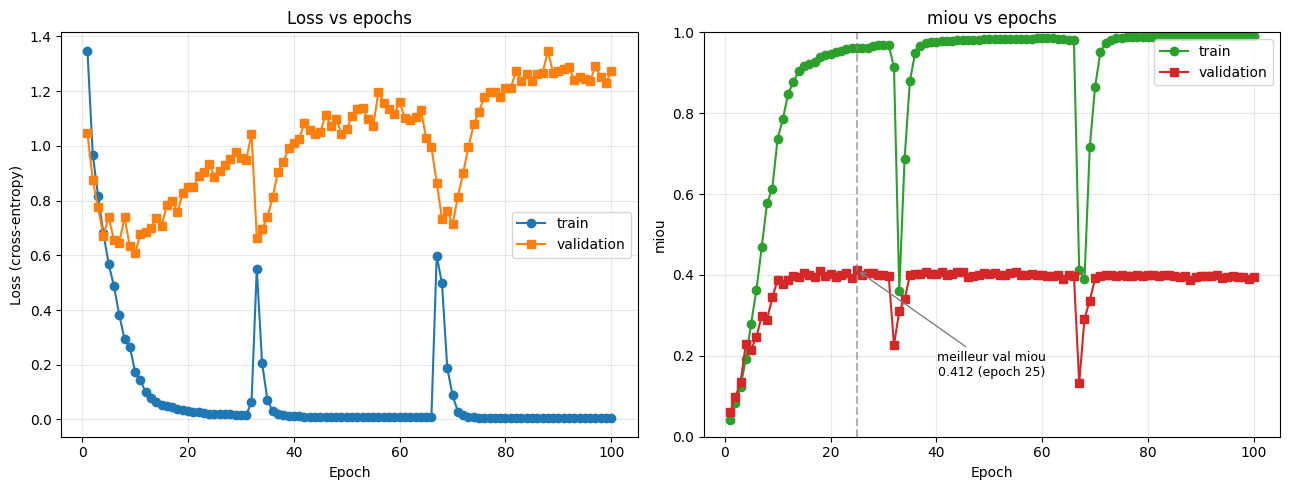

In [ ]:
_ = plot_history(history, metric_name="miou", save_path="courbes_entraînement.png")

*******************************************************************

**INFERENCE**

**Fonction utilitaires**

In [ ]:
def voc_colormap():
  # palette VOC 21 classes en valeur [0,1] pour matplotlib
  def bitget(val, idx):
    return (val >> idx) & 1

  colors = []
  for i in range(21):
    r = g = b = 0
    c = i
    for j in range(8):
      r = r | (bitget(c, 0) << 7 - j)
      g = g | (bitget(c, 1) << 7 - j)
      b = b | (bitget(c, 2) << 7 - j)
      c = c >> 3
    colors.append((r / 255, g / 255, b / 255))
  return ListedColormap(colors)

VOC_CMAP = voc_colormap()


**Chargement du modèle**



In [ ]:
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-LR1e-3.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-LR3e-4.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-LR1e-4.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-LR3e-5.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-LR1e-5.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-Drop-0-5.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-Drop-0-3.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-Drop-0-0.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-Dil-12.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-Dil-18.keras"
#PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-Dil-6.keras"
PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras"




In [ ]:
#pour memoire classification
#def load_and_preprocess_image_inference(image_path, image_size=(224, 224)):
#    """
#    Charge une image et applique le MÊME prétraitement qu'à l'entraînement.
#    Retourne un tenseur de forme (1, H, W, 3) — le 1 est la dimension de lot.
#    """
#    image = tf.io.read_file(image_path)
#    image = tf.image.decode_image(image, channels=3, expand_animations=False)
#    image = tf.image.resize(image, image_size)
#    image = tf.cast(image, tf.float32) / 255.0     # normalisation [0, 1]
#    image = tf.expand_dims(image, axis=0)          # ajoute la dimension de lot
#    return image

In [ ]:
def predict_and_show(model, data_dir, split="val", num_images = 4, ignore_label=255,
                     image_size=(IMAGE_SIZE, IMAGE_SIZE),
                     voc_cmap=VOC_CMAP, voc_names=None):

    images_dir = os.path.join(data_dir, "JPEGImages")
    #segmentation : masques png + splits du dataset dans /Segmentation/
    masks_dir = os.path.join(data_dir, "SegmentationClass")
    split_file = os.path.join(data_dir, "ImageSets", "Segmentation", f"{split}.txt")

    # Identifiants des images à afficher
    with open(split_file, "r") as f:
      ids = [line.strip() for line in f if line.strip()][:num_images]

    fig, axes = plt.subplots(len(ids), 3 , figsize=(12, 4 * len(ids)))
    if (len(ids)) ==1:
      axes = axes[np.newaxis, :]


    for i, images_id in enumerate(ids):
      # Colonne 1 : image du dataset
      pil_img = Image.open(os.path.join(images_dir, f"{images_id}.jpg")).convert("RGB")
      axes[i, 0].imshow(pil_img)
      axes[i, 0].set_title(f"Image\n{images_id}") # Corrected f-string for title
      axes[i, 0]. axis("off")

      # Colonne 2 : Masques
      mask = np.array(Image.open(os.path.join(masks_dir, f"{images_id}.png")))
      mask_disp = mask.copy()
      mask_disp[mask_disp == ignore_label] = 0
      #redimensionne le masque à la taille d'affichage (nearest) pour comparer
      axes[i, 1].imshow(mask_disp, cmap=voc_cmap, vmin=0, vmax=20)
      axes[i, 1].set_title("Masque réel")
      axes[i, 1]. axis("off")

      # Prédictions du modèles
      #on refait le prétraitmlent de l'entraînement sur l'image
      img = tf.convert_to_tensor(np.array(pil_img), dtype=tf.float32)
      img = tf.image.resize(img, image_size)
      img = preprocess_input(img)
      img = tf.expand_dims(img, 0)             # (1, H, W, 3)

      # prédiction du modèle : logits (B, H, W, 21) -> classe par pixel via argmax
      logits = model.predict(img, verbose=0)
      pred = np.argmax(logits[0], axis=-1)   # (B, H , W)

      # Colonne 3 : prédiction
      axes[i, 2].imshow(pred, cmap=VOC_CMAP, vmin=0, vmax=20)
      # Diagnostic "fond" : proportion de pixels prédit classe 0
      prop_fond = float(np.mean(pred == 0))
      axes[i, 2].set_title(f"Prédiction\n{prop_fond*100:.0f}% de fond")
      axes[i, 2]. axis("off")

    fig.tight_layout()
    plt.show()

    return fig

In [ ]:
print(f"Chargement du modèle : {PATH_MODEL_SAVED}")
model = tf.keras.models.load_model(PATH_MODEL_SAVED)

Chargement du modèle : /content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras


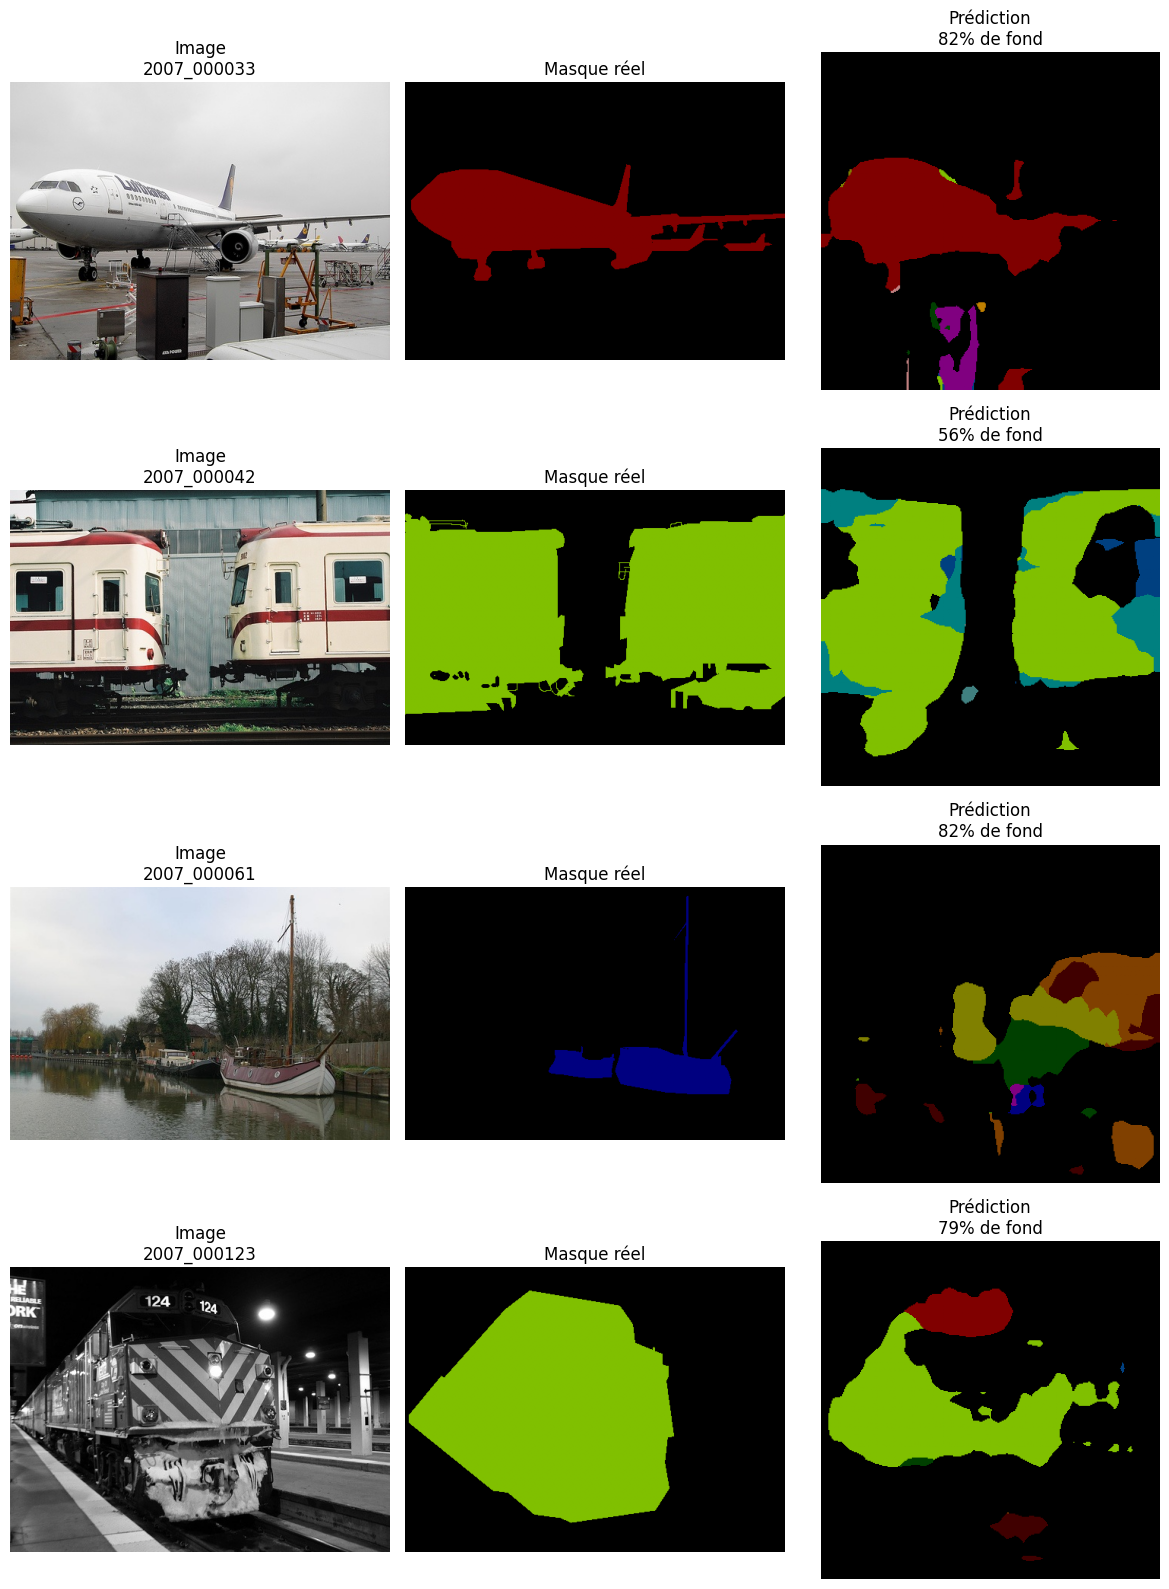

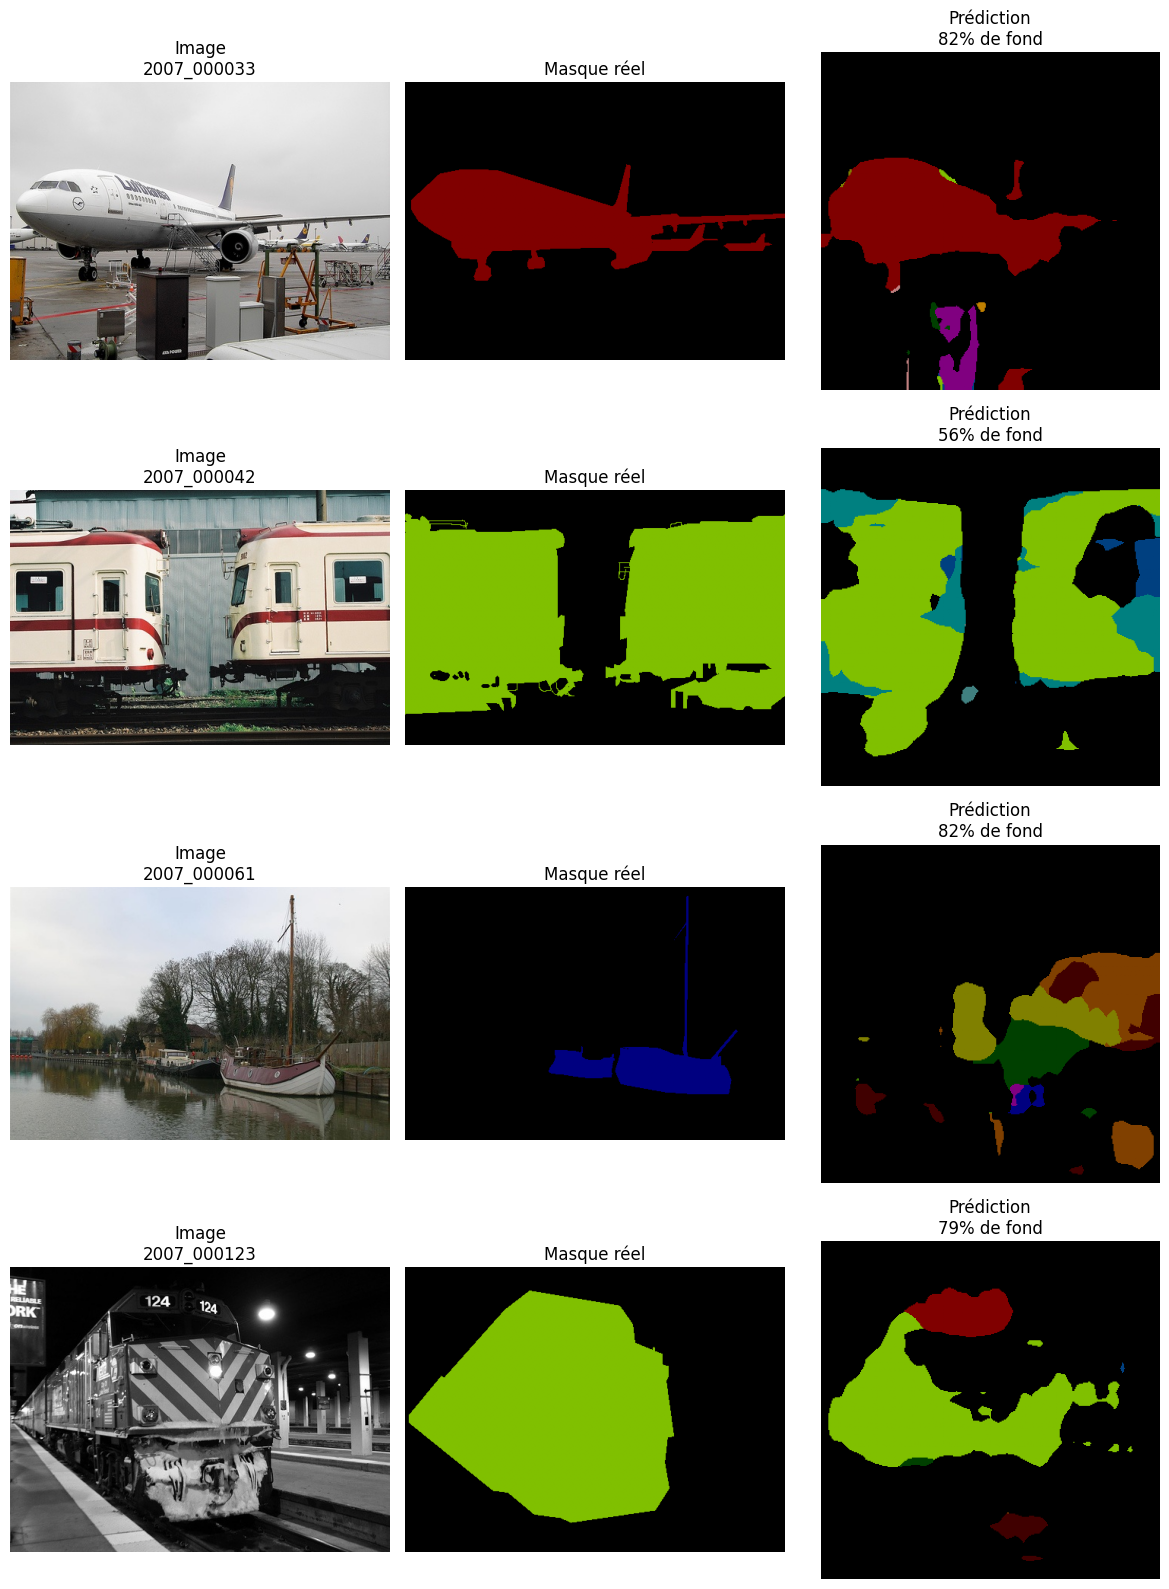

In [ ]:

predict_and_show(model, DATA_DIR, num_images = 4, ignore_label=255)

*********************************************************************OLD